### Data Understanding

#### 1. Project Overview

This project focuses on developing an end-to-end credit card fraud detection system using machine learning.

The initial implementation is based on the Kaggle Playground Series Season 6, Episode 11 competition.

The project will progressively explore statistical analysis, exploratory data analysis, feature engineering, machine learning, model evaluation, and production-oriented deployment.

#### 2. Business Problem

Credit card fraud presents a significant challenge to financial institutions because fraudulent transactions can result in financial losses, operational costs, and reduced customer trust.

The objective is to develop a machine learning model capable of identifying potentially fraudulent transactions based on transaction-related features.

The model should distinguish between legitimate and fraudulent transactions while considering the different costs associated with false positives and false negatives.

#### 3. Project Objectives

- Understand the dataset and its underlying structure.
- Investigate transaction characteristics and fraud patterns.
- Apply statistical techniques to understand the data.
- Develop and evaluate classification models.
- Explore approaches for handling class imbalance.
- Build a reproducible and deployable fraud detection system.

#### 4. Initial Scope

This notebook focuses on understanding the available datasets, identifying their structures, assessing basic data quality, and documenting initial observations.


#### STEP 1: Import Dependencies

In [53]:
# Standard library
from pathlib import Path

# Third-party libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.4f}".format)

# Reproducibility
RANDOM_STATE = 42

In [54]:
# Project configuration
# Project root
PROJECT_ROOT = Path.cwd().parent

# Data directory
DATA_DIR = PROJECT_ROOT / "data" / "raw"

# Raw dataset paths
TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"

# Verify files exist
for file_path in [
    TRAIN_PATH,
    TEST_PATH
]:
    print(f"{file_path.name}: {file_path.exists()}")

train.csv: True
test.csv: True


In [55]:
# Load datasets
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

#### STEP 2: Data Inspection

In [56]:
def check_df(df):
    # Check summary of df

    print(f"Shape: {df.shape}")

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:")
    print(df.duplicated().sum())

    print("\nFirst 5 Rows:")
    display(df.head())

check_df(train_df)

Shape: (699960, 26)

Data Types:
id                                int64
amount_usd                      float64
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
merchant_risk_score             float64
prior_disputes                    int64
merchant_category                   str
card_type                           str
auth_method                         str
channel                             str
device_type                         str
is_foreign_transaction             bool
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
is_ai_g

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.1600,9.7700,1,17.7800,48,56,1269.3500,0,5.5000,17,3,29.2000,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0000
1,1,24.8300,1.5400,3,13.0600,38,28,3233.0000,0,33.4000,23,5,29.9000,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0000
2,2,6.3600,1.2000,4,8.1700,50,55,1046.8800,0,35.8000,15,0,24.1000,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0000
3,3,37.4400,5.1300,4,8.6700,48,48,2217.6700,0,20.7000,7,3,41.9000,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0000
4,4,653.8500,0.8000,4,11.6900,37,52,3291.0600,0,34.8000,4,4,48.0000,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0000


In [57]:
# Compare dataset dimensions
print("Training:", train_df.shape)
print("Testing:", test_df.shape)


Training: (699960, 26)
Testing: (299984, 25)


#### 2.1 Target distribution

In [58]:
train_df["is_fraud"].value_counts()

is_fraud
0.0000    688271
1.0000     11689
Name: count, dtype: int64

In [59]:
train_df["is_fraud"].value_counts(normalize=True) * 100

is_fraud
0.0000   98.3300
1.0000    1.6700
Name: proportion, dtype: float64

In [60]:
# Identifier Inspection
# Inspect target values and identifier uniqueness
print("Target unique values:", train_df["is_fraud"].unique())
print("ID unique:", train_df["id"].is_unique)
print("Test ID unique:", test_df["id"].is_unique)

Target unique values: [0. 1.]
ID unique: True
Test ID unique: True


#### Initial dataset observations

The training dataset contains **699,960 transactions and 26 columns**. The test dataset contains **299,984 transactions and 25 columns**. The test set does not contain the `is_fraud` target, which is what we will eventually predict.

The `id` column is unique in both datasets. It identifies rows, rather than describing transaction behaviour, so it is excluded from the feature set.

The target contains two values: `0` for a legitimate transaction and `1` for a fraudulent transaction. Fraud represents only **1.67%** of the training data, while legitimate transactions represent **98.33%**.

**Why this matters:** The classes are highly imbalanced. A model that predicts every transaction as legitimate would appear very accurate, but it would detect no fraud. We will therefore need evaluation measures that tell us how well the model finds fraudulent transactions, not accuracy alone.


#### STEP 3: Univariate Analysis

#### 3.1 : Feature Classification

In [61]:
# Features (categorical & numerical)

features = train_df.drop(columns=["id", "is_fraud"])

features.dtypes

amount_usd                      float64
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
merchant_risk_score             float64
prior_disputes                    int64
merchant_category                   str
card_type                           str
auth_method                         str
channel                             str
device_type                         str
is_foreign_transaction             bool
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
is_ai_generated_scam_attempt       bool
dtype: object

#### 3.2 : Categorical Cardinality

In [62]:
# Categorical features

categorical_cols = features.select_dtypes(include=["str"]).columns

for col in categorical_cols:
    print(f"\n{col}")
    print(f"Unique values: {features[col].nunique()}")
    print(features[col].value_counts())


merchant_category
Unique values: 12
merchant_category
Online Retail      155097
Groceries          142578
Restaurants        101360
Fuel                59880
Electronics         48693
Streaming           47196
Utilities           42027
Healthcare          35889
Travel              28715
Gaming              23784
Gift Cards           9456
Crypto Exchange      5285
Name: count, dtype: int64

card_type
Unique values: 5
card_type
Visa          345001
Mastercard    254857
Amex           45797
RuPay          37070
Discover       17235
Name: count, dtype: int64

auth_method
Unique values: 5
auth_method
3D Secure            210036
OTP                  175178
PIN                  154020
Biometric             93666
No Authentication     67060
Name: count, dtype: int64

channel
Unique values: 5
channel
Online         273939
POS            206465
Contactless    105620
In-App          83716
ATM             30220
Name: count, dtype: int64

device_type
Unique values: 8
device_type
Android Phone    2

**What this step does**

We identify which columns contain categories and count the distinct values in each one. This helps us understand the kinds of values a column can take and later choose an appropriate way to prepare it for a model.

**What we found**

- `merchant_category` has 12 distinct categories.
- `card_type`, `auth_method` and `channel` each have 5.
- `device_type` has 8.

These are manageable numbers of categories. We have not found a categorical column with an unusually large number of distinct values in this inspection.

**Why this matters:** Most machine-learning models need categories to be converted into a numerical representation. Knowing the number of categories helps us plan that step.


#### 3.3 Missing values in features


In [63]:
# Training data
train_missing = train_df.isna().sum()

print("Training missing values:")
print(train_missing[train_missing > 0])

# Testing data
test_missing = test_df.isna().sum()

print("\nTesting missing values:")
print(test_missing[test_missing > 0])

Training missing values:
Series([], dtype: int64)

Testing missing values:
Series([], dtype: int64)


**Finding:** No missing values were reported in either the training or test dataset.

**Interpretation:** We do not currently need to plan a missing-value imputation step for these two files. We should still keep data-quality checks in the eventual training workflow so that unexpected missing values in new data are detected.


#### 3.4 Duplicate Inspection

In [64]:
# Check duplicate rows
print("Training duplicates:", train_df.duplicated().sum())
print("Testing duplicates:", test_df.duplicated().sum())

Training duplicates: 0
Testing duplicates: 0


In [65]:
print("Training duplicate IDs:", train_df["id"].duplicated().sum())
print("Testing duplicate IDs:", test_df["id"].duplicated().sum())

Training duplicate IDs: 0
Testing duplicate IDs: 0


**Finding:** There are no duplicate rows in either dataset, and the `id` column contains no duplicate identifiers in either dataset.

**Interpretation:** The checks did not identify repeated records or repeated IDs. There is no evidence from these checks that duplicate removal is needed.


#### 3.5 : Descriptive Statistics

In [66]:
features.describe().T

,count,mean,std,min,25%,50%,75%,max
amount_usd,699960.0000,79.8931,205.1735,1.0000,15.8100,27.2500,43.1100,6872.6900
hours_since_last_txn,699960.0000,6.6337,6.2901,0.0100,2.1100,4.7300,9.1900,51.9800
txn_count_last_24h,699960.0000,2.9841,1.4990,0.0000,2.0000,3.0000,4.0000,11.0000
distance_from_home_km,699960.0000,13.5876,11.6173,0.0000,4.4300,10.2200,19.7500,57.9300
card_age_months,699960.0000,46.8630,5.5792,25.0000,43.0000,47.0000,51.0000,73.0000
customer_age,699960.0000,51.4303,17.8991,18.0000,38.0000,52.0000,66.0000,81.0000
account_balance_usd,699960.0000,2064.9981,3400.1329,58.2500,834.1200,1382.7400,2517.0200,99701.3900
cvv_retry_count,699960.0000,0.0855,0.2895,0.0000,0.0000,0.0000,0.0000,3.0000
velocity_score,699960.0000,18.9294,10.8644,0.0000,11.4000,18.6000,26.0000,72.9000
time_of_day_hour,699960.0000,11.7619,6.8692,0.0000,6.0000,12.0000,18.0000,23.0000


**What this step does**

Descriptive statistics give us a numerical summary of each numeric feature: how many values it has, its average, spread, middle value, and observed minimum and maximum.

**Initial observations**

- `amount_usd` has a median of **$27.25** and a maximum of **$6,872.69**.
- `account_balance_usd` has a median of **$1,382.74** and a maximum of **$99,701.39**.
- `cvv_retry_count` and `prior_disputes` have a median of zero.
- The typical transaction has 3 transactions in the last 24 hours (`txn_count_last_24h` median = 3).

Some maximum values are much larger than the middle of their distributions. We investigate these values in the outlier section rather than assuming they are errors.


#### 3.6 : Feature Distributions

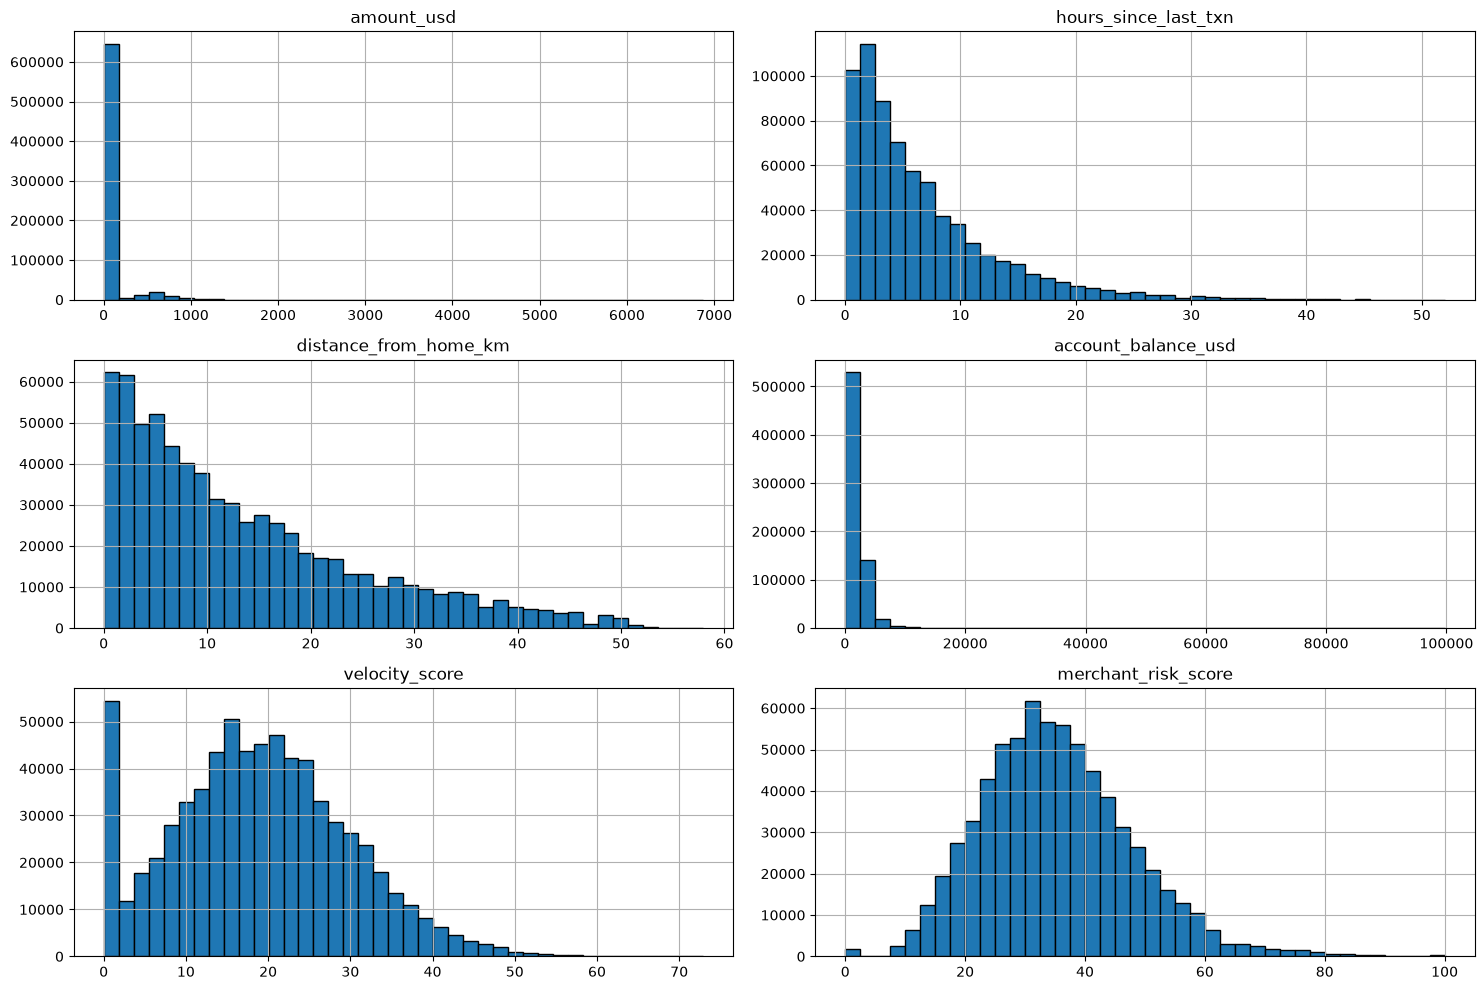

In [67]:
# Continous col features
continuous_cols = [
    "amount_usd",
    "hours_since_last_txn",
    "distance_from_home_km",
    "account_balance_usd",
    "velocity_score",
    "merchant_risk_score"
]

features[continuous_cols].hist(
    bins=40,
    figsize=(15, 10),
    edgecolor="black"
)

plt.tight_layout()
plt.show()

**What to look for in the histograms**

A histogram groups numeric values into ranges so we can see where observations are concentrated and whether a feature has a long tail or several clusters.

These plots help us understand the shape and spread of the continuous features. They are an exploratory view; the plots alone do not tell us whether an unusual value is incorrect or should be removed.


#### 3.7 : Outlier Investigation

In [68]:
outlier_summary = []

for col in continuous_cols:
    q1 = features[col].quantile(0.25)
    q3 = features[col].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (features[col] < lower_bound) |
        (features[col] > upper_bound)
    ).sum()

    outlier_summary.append({
        "feature": col,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outliers,
        "outlier_percentage": (outliers / len(features)) * 100
    })

outlier_df = pd.DataFrame(outlier_summary)

outlier_df.round(2)

,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
0,amount_usd,-25.1400,84.0600,70741,10.1100
1,hours_since_last_txn,-8.5100,19.8100,32816,4.6900
2,distance_from_home_km,-18.5500,42.7300,16770,2.4000
3,account_balance_usd,-1690.2300,5041.3700,29068,4.1500
4,velocity_score,-10.5000,47.9000,4276,0.6100
5,merchant_risk_score,1.9500,67.1500,13028,1.8600


**What this step does**

We use the IQR rule to flag unusually low or high values. The IQR is the range between the 25th percentile and the 75th percentile. Values more than 1.5 IQR below the lower quartile or above the upper quartile are flagged for review.

**Results**

| Feature | Flagged values | Percentage |
|---|---:|---:|
| `amount_usd` | 70,741 | 10.11% |
| `hours_since_last_txn` | 32,816 | 4.69% |
| `distance_from_home_km` | 16,770 | 2.40% |
| `account_balance_usd` | 29,068 | 4.15% |
| `velocity_score` | 4,276 | 0.61% |
| `merchant_risk_score` | 13,028 | 1.86% |

**Interpretation**

The IQR rule identifies values that are far from the middle of a distribution. It does not prove that those values are mistakes. In fraud detection, unusually large transactions or unusual account activity may contain useful signals.

**Decision for now:** We will not automatically delete or cap these observations. We will retain them for modelling and assess whether any treatment is justified later. Any change must be supported by the feature's meaning and model performance.


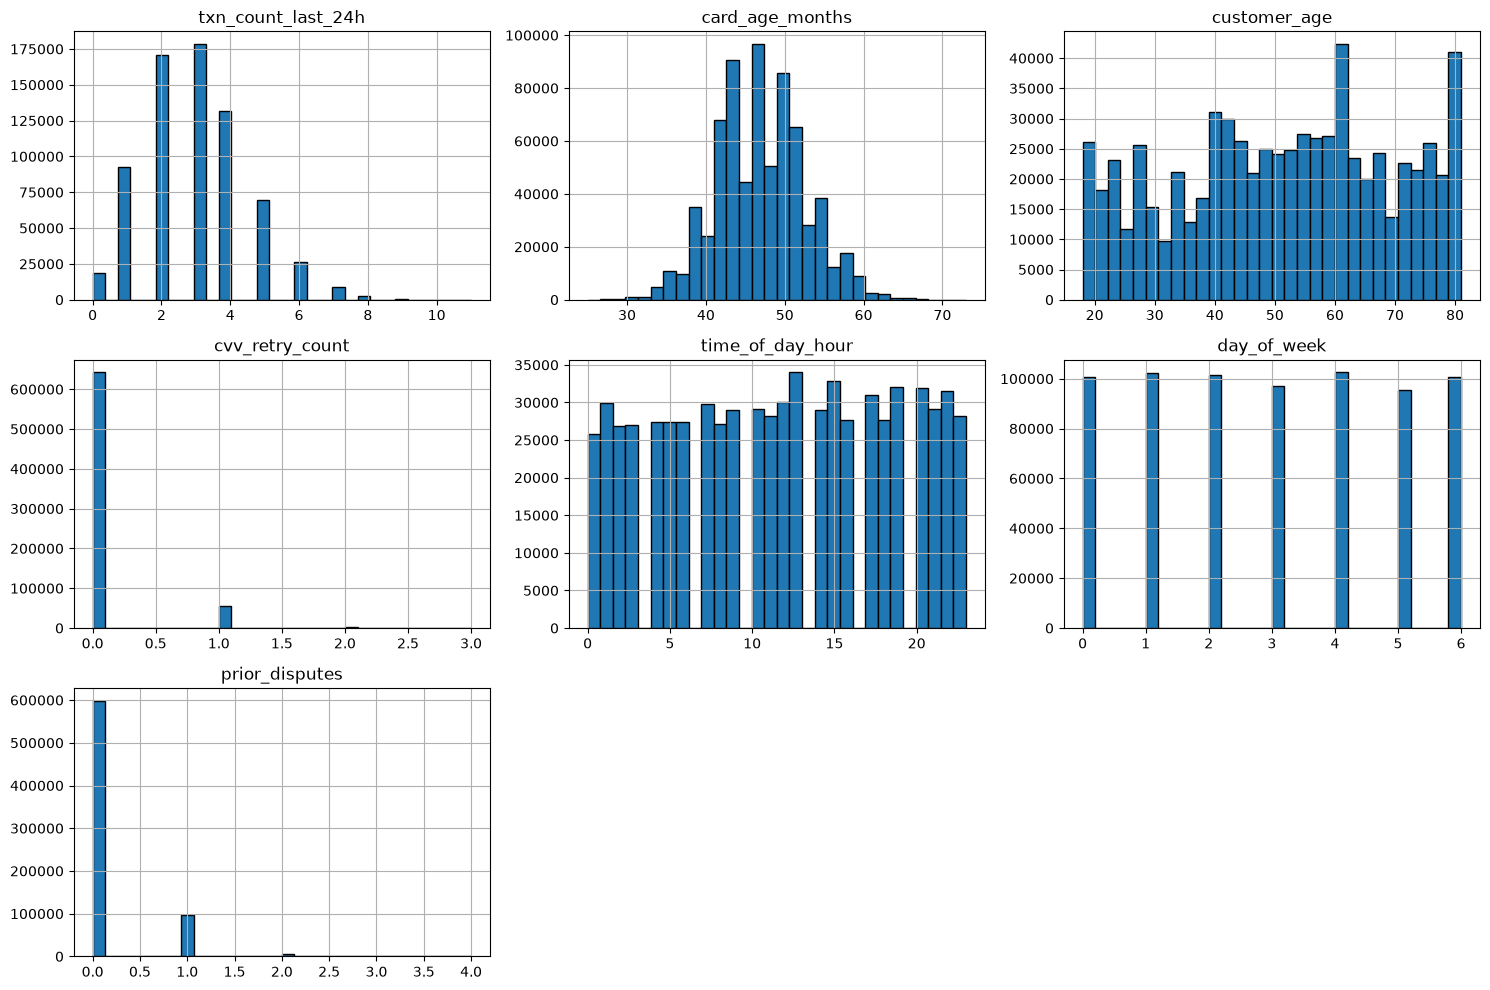

In [69]:
# Discrete col features

discrete_cols = [
    "txn_count_last_24h",
    "card_age_months",
    "customer_age",
    "cvv_retry_count",
    "time_of_day_hour",
    "day_of_week",
    "prior_disputes"
]

features[discrete_cols].hist(
    bins=30,
    figsize=(15, 10),
    edgecolor="black"
)

plt.tight_layout()
plt.show()


In [70]:
# zero-heavy features 

count_cols = [
    "txn_count_last_24h",
    "cvv_retry_count",
    "prior_disputes"
]

for col in count_cols:
    print(f"\n{col}")
    print(features[col].value_counts(normalize=True).sort_index().mul(100).round(2))


txn_count_last_24h
txn_count_last_24h
0     2.6400
1    13.2400
2    24.4000
3    25.4800
4    18.8400
5     9.9600
6     3.7800
7     1.2700
8     0.3200
9     0.0500
10    0.0100
11    0.0000
Name: proportion, dtype: float64

cvv_retry_count
cvv_retry_count
0   91.7300
1    7.9900
2    0.2700
3    0.0000
Name: proportion, dtype: float64

prior_disputes
prior_disputes
0   85.4900
1   13.7700
2    0.7200
3    0.0200
4    0.0000
Name: proportion, dtype: float64


**Additional observation: features with many zero values**

- `cvv_retry_count` is zero for **91.73%** of transactions.
- `prior_disputes` is zero for **85.49%**.
- `txn_count_last_24h` is more spread out, with most transactions having 2–4 transactions in the previous 24 hours.

The first two features are concentrated at zero, but their non-zero values may still be informative. We should not remove them simply because most records have a value of zero.


#### STEP 4: Bivariate Analysis
#### 4.1 : Numerical Features vs Target

In [71]:
count_cols = [
    "txn_count_last_24h",
    "cvv_retry_count",
    "prior_disputes"
]

for col in count_cols:
    print(f"\n{col}")

    result = (
        train_df.groupby(col)["is_fraud"]
        .agg(["count", "mean"])
        .rename(columns={"mean": "fraud_rate"})
    )

    result["fraud_percentage"] = result["fraud_rate"] * 100

    print(result.drop(columns="fraud_rate").round(2))


txn_count_last_24h
                     count  fraud_percentage
txn_count_last_24h                          
0                    18462            0.2300
1                    92705            0.6900
2                   170757            1.2800
3                   178367            1.6600
4                   131869            1.9800
5                    69701            2.5900
6                    26488            3.5100
7                     8907            4.3600
8                     2252            3.9500
9                      378            5.8200
10                      65           12.3100
11                       9           22.2200

cvv_retry_count
                  count  fraud_percentage
cvv_retry_count                          
0                642088            0.9300
1                 55942            8.7500
2                  1905           41.7300
3                    25           36.0000

prior_disputes
                 count  fraud_percentage
prior_disputes          

In [72]:
continuous_cols = [
    "amount_usd",
    "hours_since_last_txn",
    "distance_from_home_km",
    "account_balance_usd",
    "velocity_score",
    "merchant_risk_score"
]

train_df.groupby("is_fraud")[continuous_cols].median().T

is_fraud,0.0000,1.0000
amount_usd,27.2100,31.1800
hours_since_last_txn,4.7300,3.6100
distance_from_home_km,10.2200,10.3100
account_balance_usd,1382.7400,1396.0000
velocity_score,18.5000,26.6000
merchant_risk_score,34.0000,45.9000


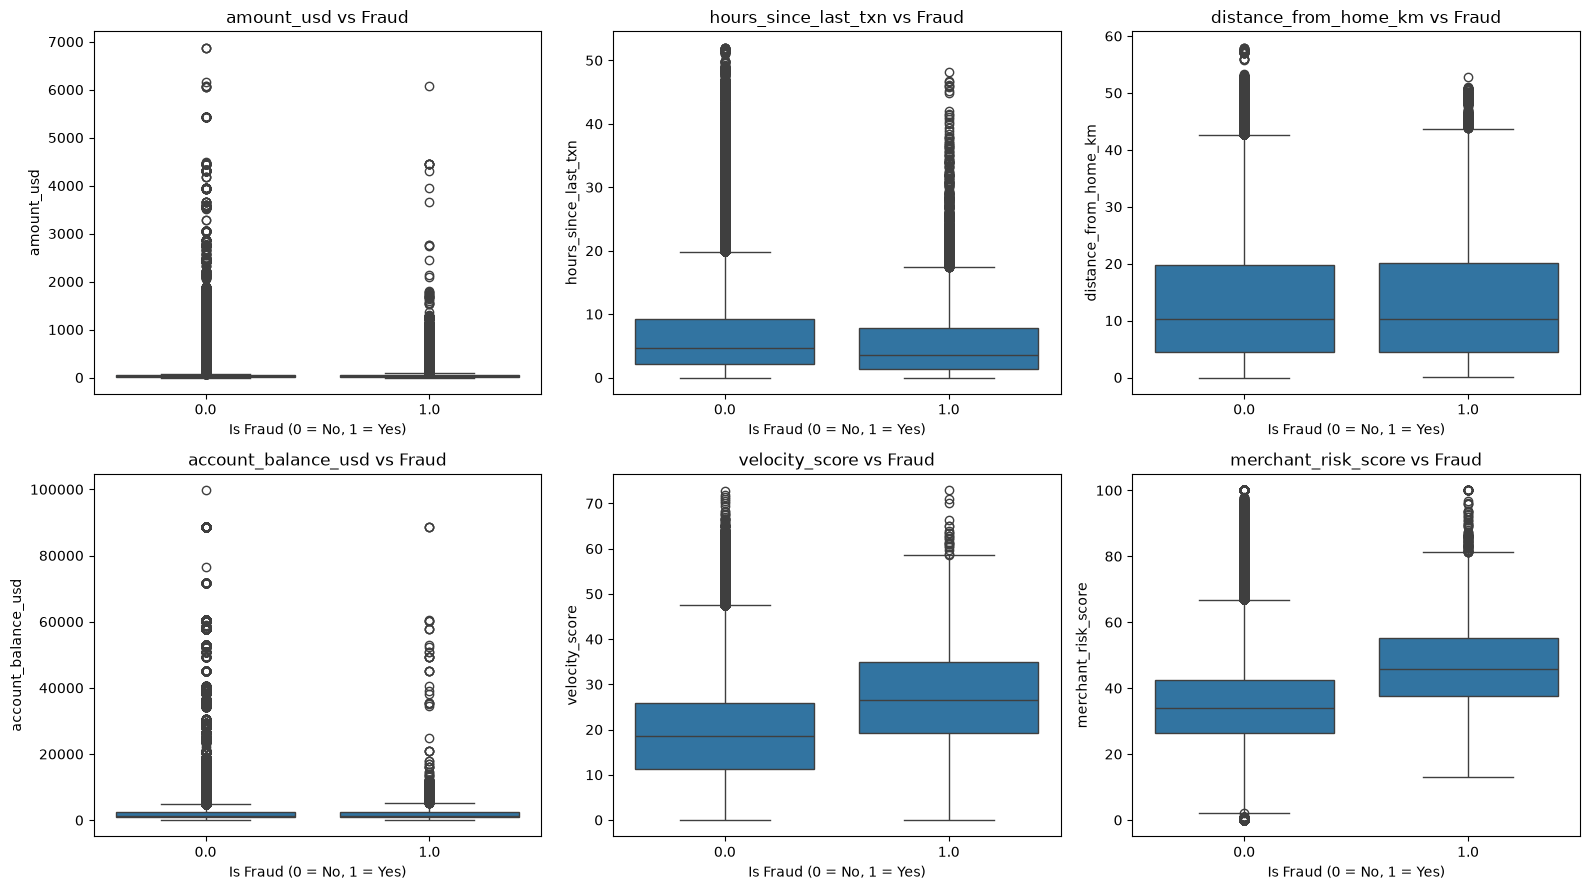

In [73]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for col, ax in zip(continuous_cols, axes.flatten()):
    sns.boxplot(
        data=train_df,
        x="is_fraud",
        y=col,
        ax=ax
    )
    ax.set_title(f"{col} vs Fraud")
    ax.set_xlabel("Is Fraud (0 = No, 1 = Yes)")

plt.tight_layout()
plt.show()

**What we compared**

For count-based features, we calculated the fraud percentage within each value. For continuous features, we compared the median values for legitimate and fraudulent transactions and used boxplots to view their distributions.

**Findings from the count features**

- Fraud percentage generally rises as `txn_count_last_24h` increases, although the highest counts have very few transactions.
- Transactions with one CVV retry have an 8.75% fraud rate, compared with 0.93% when there are no retries.
- The fraud rate is 41.73% for two CVV retries, but that group contains only 1,905 transactions; the three-retry group contains just 25 transactions.
- The fraud rate increases from 1.55% with zero prior disputes to 3.00% with two prior disputes. The groups with three or four disputes are very small.

**Findings from the continuous features**

The median `velocity_score` is higher for fraudulent transactions (26.60) than legitimate transactions (18.50). The median `merchant_risk_score` is also higher (45.90 compared with 34.00). Fraudulent transactions have a lower median `hours_since_last_txn` (3.61 compared with 4.73).

The medians for transaction amount, distance from home and account balance are closer together.

**Interpretation:** Some features show clearer differences between the two target groups than others. Very small groups can produce unstable percentages, so we must consider the transaction count alongside each fraud rate. These are observed associations, not proof that a feature causes fraud.


#### 4.2 Categorical features vs Fraud

In [74]:
categorical_cols = [
    "merchant_category",
    "card_type",
    "auth_method",
    "channel",
    "device_type"
]

for col in categorical_cols:
    print(f"\n{col}")

    result = (
        train_df.groupby(col)["is_fraud"]
        .agg(["count", "mean"])
        .rename(columns={"mean": "fraud_rate"})
    )

    result["fraud_percentage"] = result["fraud_rate"] * 100

    print(result.drop(columns="fraud_rate").round(2))


merchant_category
                    count  fraud_percentage
merchant_category                          
Crypto Exchange      5285            6.5300
Electronics         48693            3.0800
Fuel                59880            1.2400
Gaming              23784            5.5100
Gift Cards           9456            7.3000
Groceries          142578            1.1100
Healthcare          35889            1.2900
Online Retail      155097            1.1100
Restaurants        101360            1.1400
Streaming           47196            2.2500
Travel              28715            1.8600
Utilities           42027            1.3800

card_type
             count  fraud_percentage
card_type                           
Amex         45797            1.9000
Discover     17235            1.4600
Mastercard  254857            1.6000
RuPay        37070            1.6800
Visa        345001            1.7000

auth_method
                    count  fraud_percentage
auth_method                           

**Findings**

The largest fraud percentages among the merchant categories are:

- Gift Cards: **7.30%**
- Crypto Exchange: **6.53%**
- Gaming: **5.51%**
- Electronics: **3.08%**

For authentication method, transactions with **No Authentication** have a 6.44% fraud rate, while **Biometric** has 0.50%.

Fraud percentages are much closer across card types (1.46%–1.90%), channels (1.55%–1.74%) and device types (1.61%–1.73%).

**Interpretation:** Merchant category and authentication method show more visible differences in this comparison than card type, channel or device type. The counts matter too: for example, Crypto Exchange has fewer transactions than Online Retail. We should not rank categories by percentage alone or assume these patterns will remain the same in new data.


#### 4.3 Boolean features vs Fraud

In [75]:
boolean_cols = [
    "is_foreign_transaction",
    "is_new_merchant",
    "used_vpn",
    "ip_country_mismatch",
    "billing_shipping_mismatch",
    "is_ai_generated_scam_attempt"
]

In [76]:
for col in boolean_cols:
    print(f"\n{col}")

    result = (
        train_df.groupby(col)["is_fraud"]
        .agg(["count", "mean"])
        .rename(columns={"mean": "fraud_rate"})
    )

    result["fraud_percentage"] = result["fraud_rate"] * 100

    print(result.drop(columns="fraud_rate").round(2))


is_foreign_transaction
                         count  fraud_percentage
is_foreign_transaction                          
False                   687862            1.4800
True                     12098           12.5700

is_new_merchant
                  count  fraud_percentage
is_new_merchant                          
False            593240            1.1200
True             106720            4.7300

used_vpn
           count  fraud_percentage
used_vpn                          
False     676295            1.5000
True       23665            6.5500

ip_country_mismatch
                      count  fraud_percentage
ip_country_mismatch                          
False                688648            1.4300
True                  11312           16.5000

billing_shipping_mismatch
                            count  fraud_percentage
billing_shipping_mismatch                          
False                      690906            1.5200
True                         9054           12.9900

is_a

**Findings**

The fraud percentages are higher when the following indicators are present:

| Indicator | Indicator absent | Indicator present |
|---|---:|---:|
| Foreign transaction | 1.48% | 12.57% |
| New merchant | 1.12% | 4.73% |
| VPN used | 1.50% | 6.55% |
| IP-country mismatch | 1.43% | 16.50% |
| Billing/shipping mismatch | 1.52% | 12.99% |
| AI-generated scam attempt | 1.63% | 15.22% |

**Interpretation:** These indicators are associated with higher observed fraud rates in this dataset. They may be useful predictors, but we still need to check how and when each indicator is produced. A feature would create data leakage if it were only known after the transaction had already been investigated or classified.


#### 5 : Multivariate Analysis

#### 5.1 : Feature correlations

In [77]:
numerical_cols = continuous_cols + discrete_cols


In [78]:
correlation_cols = numerical_cols + ["is_fraud"]

correlation_matrix = train_df[correlation_cols].corr()

correlation_matrix

,amount_usd,hours_since_last_txn,distance_from_home_km,account_balance_usd,velocity_score,merchant_risk_score,txn_count_last_24h,card_age_months,customer_age,cvv_retry_count,time_of_day_hour,day_of_week,prior_disputes,is_fraud
amount_usd,1.0000,0.0013,0.0021,0.0198,0.0083,0.1688,0.0041,0.0042,0.0025,0.0084,0.0033,0.0044,-0.0009,0.0194
hours_since_last_txn,0.0013,1.0000,-0.0047,0.0011,-0.3440,-0.0065,-0.0384,-0.0029,-0.0108,-0.0065,-0.0031,0.0029,0.0001,-0.0205
distance_from_home_km,0.0021,-0.0047,1.0000,-0.0016,0.0038,-0.0035,0.0061,-0.0003,0.0009,0.0001,-0.0001,0.0008,-0.0003,0.0018
account_balance_usd,0.0198,0.0011,-0.0016,1.0000,0.0007,0.0098,0.0011,0.0012,0.0013,-0.0001,-0.0018,0.0042,0.0007,0.0011
velocity_score,0.0083,-0.3440,0.0038,0.0007,1.0000,0.0230,0.6214,0.0042,0.0115,0.0221,0.0014,0.0030,-0.0002,0.1016
merchant_risk_score,0.1688,-0.0065,-0.0035,0.0098,0.0230,1.0000,0.0125,0.0051,0.0087,0.0269,-0.0001,0.0062,0.0040,0.1254
txn_count_last_24h,0.0041,-0.0384,0.0061,0.0011,0.6214,0.0125,1.0000,0.0001,0.0045,0.0140,0.0041,0.0050,-0.0000,0.0580
card_age_months,0.0042,-0.0029,-0.0003,0.0012,0.0042,0.0051,0.0001,1.0000,-0.0022,0.0013,0.0006,-0.0002,-0.0001,0.0007
customer_age,0.0025,-0.0108,0.0009,0.0013,0.0115,0.0087,0.0045,-0.0022,1.0000,0.0155,0.0014,-0.0006,0.0021,0.0561
cvv_retry_count,0.0084,-0.0065,0.0001,-0.0001,0.0221,0.0269,0.0140,0.0013,0.0155,1.0000,0.0004,0.0024,0.0070,0.2123


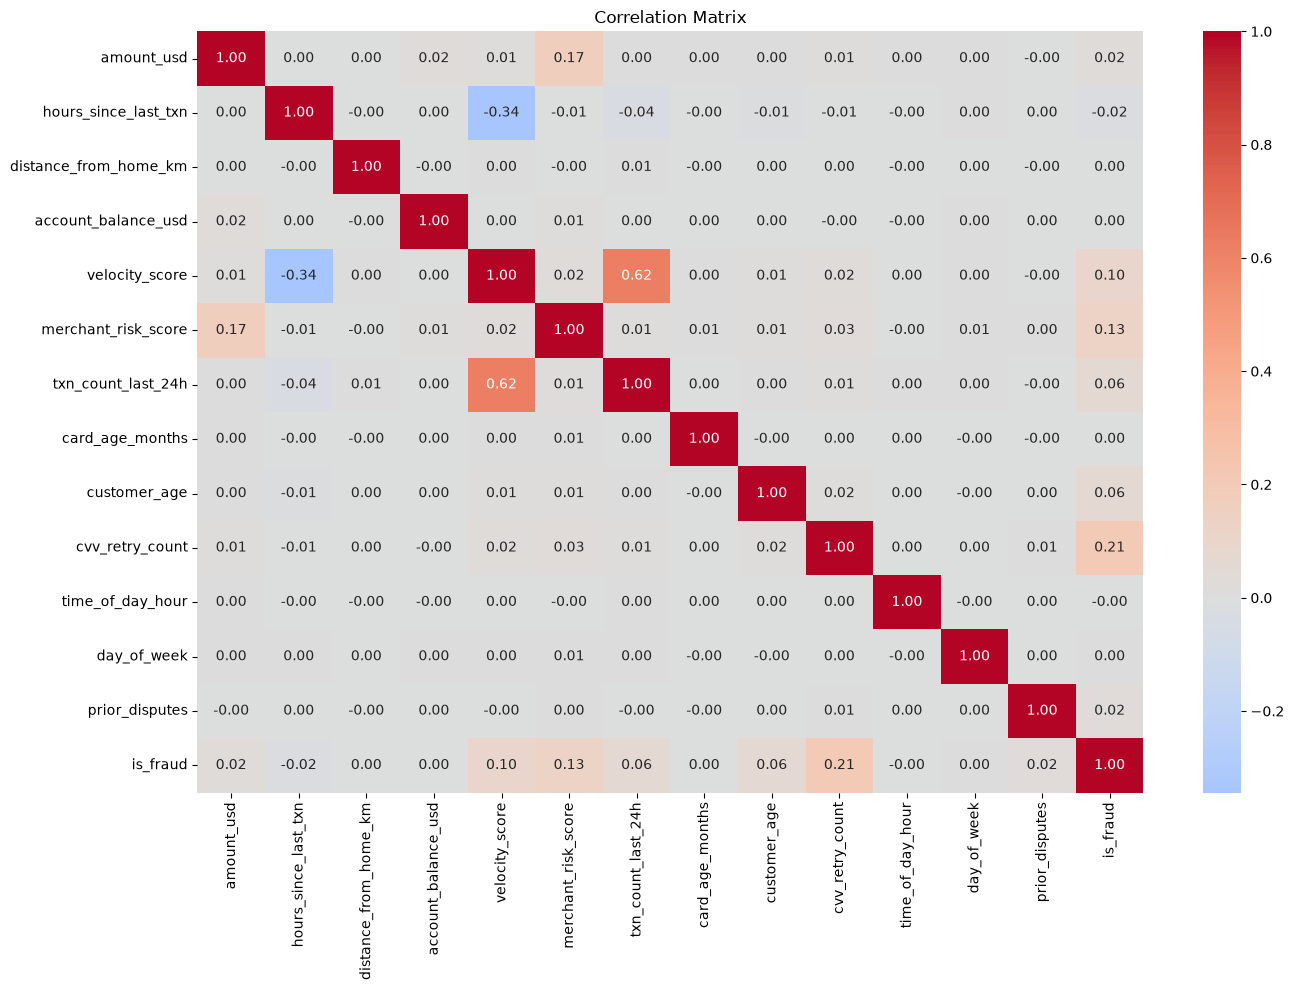

In [79]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

**Main observations**

- `velocity_score` and `txn_count_last_24h` have a correlation of **0.6214**.
- `hours_since_last_txn` and `velocity_score` have a correlation of **-0.3440**.
- Most other predictor pairs have correlations close to zero.
- The largest correlations with `is_fraud` in this numeric-only matrix are `cvv_retry_count` (**0.2123**), `merchant_risk_score` (**0.1254**) and `velocity_score` (**0.1016**).

**Important limitations:** Correlation does not establish cause and effect. A low correlation does not mean a feature is useless, because a feature may be useful through non-linear patterns or interactions. This matrix includes numeric columns only, so it does not evaluate relationships involving the string categories or Boolean indicators.


#### 5.2 Feature interactions

In [80]:
# used_vpn and ip_country_mismatch
train_df.groupby(
    ["used_vpn", "ip_country_mismatch"]
)["is_fraud"].agg(
    transaction_count="count",
    fraud_rate="mean"
).assign(
    fraud_percentage=lambda x: x["fraud_rate"] * 100
).drop(
    columns="fraud_rate"
).round(2)

transaction_count  fraud_percentage
used_vpn ip_country_mismatch                                     
False    False                           665571            1.2800
         True                             10724           15.0000
True     False                            23077            5.6000
         True                               588           43.7100

In [81]:
# # Cross-tabulation of the two binary features against fraud
# pd.crosstab(
#     [train_df["is_foreign_transaction"], train_df["billing_shipping_mismatch"]],
#     train_df["is_fraud"],
#     normalize="index"
# ) * 100

In [82]:
# is_foreign_transaction and billing_shipping_mismatch

train_df.groupby(
    ["is_foreign_transaction", "billing_shipping_mismatch"]
)["is_fraud"].agg(
    transaction_count="count",
    fraud_rate="mean"
).assign(
    fraud_percentage=lambda x: x["fraud_rate"] * 100
).drop(
    columns="fraud_rate"
).round(2)

transaction_count  \
is_foreign_transaction billing_shipping_mismatch                      
False                  False                                 679056   
                       True                                    8806   
True                   False                                  11850   
                       True                                     248   

                                                  fraud_percentage  
is_foreign_transaction billing_shipping_mismatch                    
False                  False                                1.3400  
                       True                                11.8900  
True                   False                               11.7500  
                       True                                52.0200

In [83]:
# is_new_merchant and merchant_risk_score

train_df.groupby("is_new_merchant")["merchant_risk_score"].describe()


,count,mean,std,min,25%,50%,75%,max
is_new_merchant,,,,,,,,
False,593240.0000,35.1700,12.6078,0.0000,26.4000,34.1000,42.7000,100.0000
True,106720.0000,35.4825,12.7388,0.0000,26.6000,34.4000,43.0000,100.0000


In [84]:
# is_new_merchant and merchant_risk_score vs fraud

train_df.groupby("is_new_merchant").agg(
    transaction_count=("is_fraud", "size"),
    fraud_count=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean")
)

,transaction_count,fraud_count,fraud_rate
is_new_merchant,,,
False,593240,6637.0000,0.0112
True,106720,5052.0000,0.0473


In [85]:
train_df["merchant_risk_band"] = pd.cut(
    train_df["merchant_risk_score"],
    bins=[-1, 25, 50, 75, 100],
    labels=["Low", "Moderate", "High", "Very High"]
)

pd.crosstab(
    [train_df["is_new_merchant"], train_df["merchant_risk_band"]],
    train_df["is_fraud"],
    normalize="index"
).mul(100).rename(columns={0: "legitimate_pct", 1: "fraud_pct"})

is_fraud                            legitimate_pct  fraud_pct
is_new_merchant merchant_risk_band                           
False           Low                        99.8509     0.1491
                Moderate                   98.9942     1.0058
                High                       96.7701     3.2299
                Very High                  92.3528     7.6472
True            Low                        99.3046     0.6954
                Moderate                   95.6221     4.3779
                High                       87.5041    12.4959
                Very High                  73.6597    26.3403

In [86]:
train_df.groupby(
    ["is_new_merchant", "merchant_risk_band"],
    observed=True
).agg(
    transaction_count=("is_fraud", "size"),
    fraud_count=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean")
).assign(
    fraud_rate=lambda x: x["fraud_rate"] * 100
)

transaction_count  fraud_count  fraud_rate
is_new_merchant merchant_risk_band                                            
False           Low                            125381     187.0000      0.1491
                Moderate                       397897    4002.0000      1.0058
                High                            65699    2122.0000      3.2299
                Very High                        4263     326.0000      7.6472
True            Low                             22003     153.0000      0.6954
                Moderate                        71519    3131.0000      4.3779
                High                            12340    1542.0000     12.4959
                Very High                         858     226.0000     26.3403

In [87]:
# is_foreign_transaction and ip_country_mismatch vs fraud

train_df.groupby(
    ["is_foreign_transaction", "ip_country_mismatch"]
).agg(
    transaction_count=("is_fraud", "size"),
    fraud_count=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean")
).assign(
    fraud_rate_pct=lambda x: x["fraud_rate"] * 100
)

transaction_count  fraud_count  \
is_foreign_transaction ip_country_mismatch                                   
False                  False                           680081    9216.0000   
                       True                              7781     952.0000   
True                   False                             8567     607.0000   
                       True                              3531     914.0000   

                                            fraud_rate  fraud_rate_pct  
is_foreign_transaction ip_country_mismatch                              
False                  False                    0.0136          1.3551  
                       True                     0.1223         12.2349  
True                   False                    0.0709          7.0853  
                       True                     0.2589         25.8850

In [88]:
# used_vpn and is_foreign_transaction vs fraud

train_df.groupby(
    ["is_foreign_transaction", "used_vpn"]
).agg(
    transaction_count=("is_fraud", "size"),
    fraud_count=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean")
).assign(
    fraud_rate_pct=lambda x: x["fraud_rate"] * 100
)

transaction_count  fraud_count  fraud_rate  \
is_foreign_transaction used_vpn                                               
False                  False                664743    8819.0000      0.0133   
                       True                  23119    1349.0000      0.0584   
True                   False                 11552    1320.0000      0.1143   
                       True                    546     201.0000      0.3681   

                                 fraud_rate_pct  
is_foreign_transaction used_vpn                  
False                  False             1.3267  
                       True              5.8350  
True                   False            11.4266  
                       True             36.8132

In [89]:
# is_new_merchant and is_ai_generated_Scam_attempt vs fraud
train_df.groupby(
    ["is_new_merchant", "is_ai_generated_scam_attempt"]
)["is_fraud"].agg(
    transaction_count="count",
    fraud_count="sum",
    fraud_rate="mean"
).assign(
    fraud_rate_pct=lambda x: x["fraud_rate"] * 100
)

transaction_count  fraud_count  \
is_new_merchant is_ai_generated_scam_attempt                                   
False           False                                    591377    6449.0000   
                True                                       1863     188.0000   
True            False                                    106284    4890.0000   
                True                                        436     162.0000   

                                              fraud_rate  fraud_rate_pct  
is_new_merchant is_ai_generated_scam_attempt                              
False           False                             0.0109          1.0905  
                True                              0.1009         10.0913  
True            False                             0.0460          4.6009  
                True                              0.3716         37.1560

**What we investigated**

We compared selected pairs of indicators to see whether their combination was associated with a different fraud percentage from either indicator considered alone.

**Findings**

- When both VPN use and IP-country mismatch are absent, the fraud rate is **1.28%** (665,571 transactions). When both are present, it is **43.71%** (588 transactions).
- When both foreign-transaction status and billing/shipping mismatch are present, the fraud rate is **52.02%** (248 transactions). The rate is 11.89% when only the mismatch is present and 11.75% when only the transaction is foreign.
- For new merchants, the fraud rate rises across the merchant-risk bands: from **0.70%** in the low-risk band to **26.34%** in the very-high-risk band. The very-high-risk, new-merchant group contains 858 transactions.
- The combination of a new merchant and an AI-generated scam-attempt flag has a fraud rate of **37.16%**, based on 436 transactions.

**Interpretation**

These combinations reveal patterns that are not as visible when looking at one feature at a time. Some combinations have very high fraud percentages but relatively few transactions. We should therefore consider both the fraud percentage and the group size, and treat these findings as associations rather than proof of causation.

The `merchant_risk_band` column was created here to support exploration. It is not yet a finalized production feature. If we decide to use this grouping during modelling, we must apply the same boundaries and labels consistently to both training and test data.


In [90]:
# Investigating multicollinearity using Variance Inflation Factor (VIF)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = train_df.select_dtypes(include="number").drop(
    columns=["is_fraud", "id"],
    errors="ignore"
)

vif_data = pd.DataFrame({
    "feature": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
}).sort_values("VIF", ascending=False)

vif_data

,feature,VIF
8,velocity_score,1.9576
2,txn_count_last_24h,1.7275
1,hours_since_last_txn,1.2027
11,merchant_risk_score,1.0307
0,amount_usd,1.0298
7,cvv_retry_count,1.0015
5,customer_age,1.0005
6,account_balance_usd,1.0005
10,day_of_week,1.0001
3,distance_from_home_km,1.0001


#### 5.3 Multicollinearity check using VIF

**What VIF tells us**

Some numeric features may contain overlapping information. Variance Inflation Factor (VIF) is one way to check how much a feature can be explained by the other numeric features in the same analysis. A high value can indicate that predictors overlap substantially.

**Findings**

The largest VIF values are:

- `velocity_score`: **1.9576**
- `txn_count_last_24h`: **1.7275**
- `hours_since_last_txn`: **1.2027**

All remaining numeric features have VIF values close to 1.

**Interpretation:** The results do not indicate a serious multicollinearity problem among the numeric predictors included in this calculation. We do not have a VIF-based reason to remove any of these features at this stage.

This calculation covers numeric predictors only. It does not assess overlap among the categorical or Boolean features.


#### 6. Exploratory Data Analysis: Summary and next steps

##### Dataset quality

The training and test datasets contain no reported missing values or duplicate rows. The `id` values are unique in both datasets. The training target contains 11,689 fraudulent transactions (1.67%) and 688,271 legitimate transactions (98.33%).

##### Main patterns observed

- Fraudulent transactions have higher median velocity and merchant-risk scores than legitimate transactions.
- Higher CVV retry counts and transaction counts are associated with higher observed fraud percentages, although the largest count groups contain relatively few records.
- Gift Cards, Crypto Exchange and Gaming have higher fraud percentages than most other merchant categories in this dataset.
- No Authentication has a higher observed fraud percentage than the other authentication methods.
- Foreign transactions, VPN use, IP-country mismatch, billing/shipping mismatch and the AI-generated scam-attempt flag are each associated with higher fraud percentages.
- Selected combinations of these indicators show even higher fraud percentages. Some of those combinations are rare, so their rates need to be interpreted with their group sizes.

##### Data preparation considerations

1. The target is strongly imbalanced. Model evaluation must focus on fraud detection rather than accuracy alone.
2. Categorical columns will need an appropriate encoding approach before they can be used by most machine-learning models.
3. Scaling may be useful for some model families, but it is not automatically required for every algorithm.
4. The IQR analysis flagged unusual values, but we have not established that they are data errors. We will not remove them automatically.
5. The numeric correlation and VIF results do not show severe overlap among the numeric predictors.
6. Before modelling, we must verify that every feature would genuinely be available at the moment a transaction needs to be assessed. This helps prevent data leakage.
7. Any feature transformation created during exploration, including `merchant_risk_band`, must be applied consistently using training-derived rules.

##### Limitations of this EDA

The comparisons in this notebook are descriptive. They show patterns in the available training data, but they do not prove that a feature causes fraud or that the same rates will occur in future transactions. We have not yet established predictive value through a validation model.

##### Conclusion

The dataset is structurally complete based on the checks performed, but it has a substantial class imbalance. Several transaction, merchant and security indicators show useful differences in observed fraud rates. These findings provide a basis for the next stage: preparing features, creating a leakage-aware validation strategy and establishing a baseline classification model.
